# Cozy meets ...? — Steam tag white-space network
MADT 7202 mid-term · evidence notebook. Every number on the one-page report is written to
`outputs/numbers.json` by this notebook. Rules are fixed in `src/tagnet.py` (pre-registered in `docs/PLAN.md`).

**Decision:** which two-tag concept the creative director of a hypothetical 5-person Bangkok indie studio
pitches at the next greenlight meeting.

**Sources:** S1 = FronkonGames Steam Games Dataset (MIT) — sampling frame + snapshot tags and reviews;
S2 = live Steam store pull (user tags with votes from the app page, review totals from `appreviews`).
S2 is primary; S1 is used to triangulate. SteamSpy was also pulled but mirrors S1 exactly (shown below),
so it is not an independent source.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import tagnet as tn

OUT = ROOT / "outputs"
(OUT / "tables").mkdir(parents=True, exist_ok=True)
NUM = {}  # every number used on the page
pd.set_option("display.width", 160)

games = tn.load_games()
pop = pd.read_csv(ROOT / "data/processed/population.csv")
games = games[games["s2_tags"].map(len) > 0].reset_index(drop=True)
NUM.update(population=len(pop), sampled=1000, analysed=len(games),
           fetched_from=games["fetched"].min()[:10], fetched_to=games["fetched"].max()[:10],
           median_reviews=float(games["s2_reviews"].median()))
print(NUM)

{'population': 9094, 'sampled': 1000, 'analysed': 996, 'fetched_from': '2026-10-14', 'fetched_to': '2026-10-14', 'median_reviews': 51.0}


## 1 · Triangulation: S1 snapshot vs S2 live pull

In [2]:
def jacc(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else np.nan

def top5(d):
    return [t for t in d if t not in tn.SEED_TAGS][:5]

j5 = [jacc(top5(a), top5(b)) for a, b in zip(games["s1_tags"], games["s2_tags"])]
rho = spearmanr(games["reviews"], games["s2_reviews"]).statistic
ss = games["ss_tags"].notna()
j5_ss = [jacc(top5(a), top5(b)) for a, b in zip(games.loc[ss, "s1_tags"], games.loc[ss, "ss_tags"])]
NUM.update(tri_top5_jaccard=float(np.nanmean(j5)), tri_top5_identical=float(np.mean(np.array(j5) == 1)),
           tri_reviews_spearman=float(rho),
           review_growth=float(games["s2_reviews"].sum() / games["reviews"].sum()),
           steamspy_vs_s1_jaccard=float(np.nanmean(j5_ss)),
           steamspy_vs_s1_reviews_equal=float((games.loc[ss, "ss_reviews"] == games.loc[ss, "reviews"]).mean()))
print({k: round(NUM[k], 3) for k in ["tri_top5_jaccard", "tri_top5_identical", "tri_reviews_spearman",
                                     "review_growth", "steamspy_vs_s1_jaccard", "steamspy_vs_s1_reviews_equal"]})

{'tri_top5_jaccard': 0.869, 'tri_top5_identical': 0.711, 'tri_reviews_spearman': 0.977, 'review_growth': 1.254, 'steamspy_vs_s1_jaccard': 1.0, 'steamspy_vs_s1_reviews_equal': 1.0}


## 2 · The seed and generic-tag trap
"Indie" is the collection seed. Tags in > 25 % of games are generic (rule fixed in advance).

In [3]:
tag_lists = [list(d) for d in games["s2_tags"]]
indie_share = np.mean(["Indie" in t for t in tag_lists])
generic, dfreq = tn.generic_tags(tag_lists, tn.DEFAULTS["generic_df"])
gen_table = pd.Series(dfreq).sort_values(ascending=False).head(20).rename("doc_freq").to_frame()
gen_table["generic"] = gen_table.index.isin(generic)
NUM.update(indie_share=float(indie_share), generic=sorted(generic, key=lambda t: -dfreq[t]),
           n_generic=len(generic))
gen_table.round(3)

,doc_freq,generic
Singleplayer,0.770,True
Adventure,0.473,True
Casual,0.436,True
Action,0.418,True
2D,0.392,True
3D,0.344,True
Atmospheric,0.298,True
Exploration,0.292,True
Simulation,0.284,True
First-Person,0.254,True


## 3 · Graph construction (K = 5 tags per game, NPMI ≥ 0.10, co-occur ≥ 5, tag ≥ 15 games)

In [4]:
reviews = games["s2_reviews"].values
dicts = list(games["s2_tags"])
R = tn.run(dicts, reviews)
G, pairs = R["G"], R["pairs"]
n_tags_raw = len({t for d in dicts for t in d})
NUM.update(nodes=G.number_of_nodes(), edges=G.number_of_edges(), tags_before=n_tags_raw)
print(f"{n_tags_raw} distinct tags before pruning -> {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

391 distinct tags before pruning -> 98 nodes, 249 edges


### Named alternative (a): raw co-occurrence count instead of NPMI
Raw count is computed on the *uncleaned* top-5 tags (what a naive build sees).

In [5]:
naive = [[t for t in tags if t not in tn.SEED_TAGS][:5] for tags in tag_lists]
n_a, n_ab = tn.cooccurrence(naive)
top5_common = [t for t, _ in n_a.most_common(5)]
raw_top = sorted(n_ab.items(), key=lambda kv: -kv[1])[:10]
raw_touch = sum(a in top5_common or b in top5_common for (a, b), _ in raw_top)
npmi_top = sorted(G.edges(data=True), key=lambda e: -e[2]["npmi"])[:10]
npmi_touch = sum(a in top5_common or b in top5_common for a, b, _ in npmi_top)
NUM.update(top5_common=top5_common, raw_top10_touch_common=raw_touch, npmi_top10_touch_common=npmi_touch,
           raw_top_edge=list(raw_top[0][0]), raw_top_edge_count=raw_top[0][1])
print("5 most common tags:", top5_common)
print("raw-count top-10 edges:", raw_top)
print("NPMI top-10 edges:", [(a, b, round(d["npmi"], 2)) for a, b, d in npmi_top])

5 most common tags: ['Adventure', 'Casual', 'Action', 'Simulation', 'Puzzle']
raw-count top-10 edges: [(('Action', 'Adventure'), 66), (('Horror', 'Psychological Horror'), 55), (('Casual', 'Simulation'), 50), (('Adventure', 'Casual'), 47), (('Adventure', 'Puzzle'), 46), (('Casual', 'Puzzle'), 39), (('Action', 'Casual'), 39), (('Adventure', 'RPG'), 38), (('Action-Adventure', 'Adventure'), 34), (('Adventure', 'Horror'), 34)]
NPMI top-10 edges: [('Deckbuilding', 'Roguelike Deckbuilder', np.float64(0.71)), ('Card Battler', 'Card Game', np.float64(0.71)), ('Action Roguelike', 'Bullet Hell', np.float64(0.66)), ('Horror', 'Psychological Horror', np.float64(0.65)), ('Turn-Based Tactics', 'Turn-Based Strategy', np.float64(0.64)), ('2D Platformer', 'Platformer', np.float64(0.63)), ('Multiplayer', 'Online Co-Op', np.float64(0.63)), ('Card Game', 'Roguelike Deckbuilder', np.float64(0.63)), ('Platformer', 'Precision Platformer', np.float64(0.63)), ('Anime', 'JRPG', np.float64(0.59))]


## 4 · Structure: who brokers between neighbourhoods? (betweenness on 1−NPMI distance, Burt constraint)

In [6]:
brokers = tn.broker_table(G)
brokers.to_csv(OUT / "tables/brokers.csv")
brokers.head(10).round(3)

,betweenness,constraint,degree,games
tag,,,,
Puzzle,0.173,0.131,14,172
Arcade,0.134,0.140,12,71
Strategy,0.127,0.145,17,119
RPG,0.099,0.195,12,133
Relaxing,0.085,0.173,10,61
Roguelite,0.082,0.207,13,77
Horror,0.076,0.258,14,145
Turn-Based Tactics,0.073,0.358,5,22
Colorful,0.065,0.233,7,61


## 5 · White space: under-supplied pairs that bridge disjoint neighbourhoods and perform

In [7]:
pairs.to_csv(OUT / "tables/pairs.csv", index=False)
elig = pairs[pairs["eligible"]].reset_index(drop=True)
print(len(pairs), "scored pairs;", len(elig), "eligible")
elig.head(10).round(2)

148 scored pairs; 24 eligible


,a,b,n_ab,expected,saturation,median_reviews,lift,hit_rate,overlap,npmi,eligible
0,Puzzle,Story Rich,9,11.40,0.79,302.0,5.92,0.22,0.10,-0.05,True
1,Pixel Graphics,Strategy,11,10.39,1.06,283.0,5.55,0.09,0.00,0.01,True
2,Pixel Graphics,Roguelite,9,6.73,1.34,166.0,3.25,0.00,0.09,0.06,True
3,RPG,Roguelike,9,8.15,1.10,143.0,2.80,0.11,0.00,0.02,True
4,RPG,Roguelite,10,10.28,0.97,91.5,1.79,0.10,0.00,-0.01,True
5,Dark,Puzzle,9,7.77,1.16,87.0,1.71,0.22,0.11,0.03,True
6,Cute,Pixel Graphics,10,7.60,1.32,83.5,1.64,0.10,0.00,0.06,True
7,Pixel Graphics,RPG,13,11.62,1.12,79.0,1.55,0.08,0.05,0.03,True
8,Puzzle,RPG,9,22.97,0.39,79.0,1.55,0.22,0.00,-0.20,True
9,RPG,Story Rich,13,8.81,1.48,53.0,1.04,0.00,0.18,0.09,True


In [8]:
estab = pairs[pairs["saturation"] > tn.DEFAULTS["max_sat"]].reset_index(drop=True)  # fallback pool
estab.head(5).round(2)

,a,b,n_ab,expected,saturation,median_reviews,lift,hit_rate,overlap,npmi,eligible
0,Management,Strategy,9,3.82,2.35,662.0,12.98,0.44,0.10,0.18,False
1,Building,Sandbox,15,1.57,9.53,577.0,11.31,0.27,0.38,0.54,False
2,Anime,Story Rich,10,3.51,2.85,514.5,10.09,0.40,0.30,0.23,False
3,Building,Strategy,13,3.82,3.40,429.0,8.41,0.31,0.16,0.28,False
4,Mystery,Story Rich,9,2.85,3.16,241.0,4.73,0.11,0.17,0.24,False


## 6 · Robustness

In [9]:
def rank_of(pair, pairs_df):
    e = pairs_df[pairs_df["eligible"]].reset_index(drop=True)
    for i, r in enumerate(e.itertuples(), 1):
        if tuple(sorted((r.a, r.b))) == pair:
            return i
    return None

best = tuple(sorted((elig.loc[0, "a"], elig.loc[0, "b"])))
runner = tuple(sorted((elig.loc[1, "a"], elig.loc[1, "b"])))
sweep = []
for cut in [0.05, 0.10, 0.15, 0.20]:
    for mc in [5, 10]:
        sweep.append({"param": f"NPMI>={cut}, co>={mc}", "rank": rank_of(best, tn.run(dicts, reviews, npmi_cut=cut, min_co=mc)["pairs"])})
for k in [5, 10, 20]:
    sweep.append({"param": f"K={k}", "rank": rank_of(best, tn.run(dicts, reviews, k=k)["pairs"])})
for gdf in [0.20, 0.25, 0.35]:
    sweep.append({"param": f"generic>{gdf:.0%}", "rank": rank_of(best, tn.run(dicts, reviews, generic_df=gdf)["pairs"])})
s1_ok = games["s1_tags"].map(lambda d: isinstance(d, dict) and len(d) > 0)
sweep.append({"param": "S1 tags (snapshot)",
              "rank": rank_of(best, tn.run(list(games.loc[s1_ok, "s1_tags"]), games.loc[s1_ok, "reviews"].values)["pairs"])})
sweep = pd.DataFrame(sweep)
p20 = tn.run(dicts, reviews, k=20)["pairs"]
r20 = p20[(p20.a.isin(best)) & (p20.b.isin(best))].iloc[0]
NUM.update(k20_n=int(r20.n_ab), k20_lift=float(r20.lift), k20_sat=float(r20.saturation))
sweep.to_csv(OUT / "tables/robustness_sweep.csv", index=False)
sweep

,param,rank
0,"NPMI>=0.05, co>=5",1.0
1,"NPMI>=0.05, co>=10",1.0
2,"NPMI>=0.1, co>=5",1.0
3,"NPMI>=0.1, co>=10",1.0
4,"NPMI>=0.15, co>=5",1.0
5,"NPMI>=0.15, co>=10",1.0
6,"NPMI>=0.2, co>=5",1.0
7,"NPMI>=0.2, co>=10",1.0
8,K=5,1.0
9,K=10,NaN


In [10]:
# Bootstrap: resample games. Rank = is the pair still the top eligible pair? Lift = the pair's games' median
# reviews / cohort median, computed directly so resamples where n_AB < 8 still count.
rng = np.random.default_rng(7202)
has_pair = np.array([set(best) <= set(b) for b in R["baskets"]])
boot_rank, boot_lift = [], []
for _ in range(100):
    i = rng.integers(0, len(games), len(games))
    pr = tn.run([dicts[j] for j in i], reviews[i])["pairs"]
    boot_rank.append(rank_of(best, pr))
    r_i, h_i = reviews[i], has_pair[i]
    boot_lift.append(np.median(r_i[h_i]) / np.median(r_i) if h_i.any() else np.nan)
boot_rank = pd.Series(boot_rank, dtype="float")
boot_lift = np.array(boot_lift)
NUM.update(boot_top1=int((boot_rank == 1).sum()), boot_top3=int((boot_rank <= 3).sum()),
           boot_lift_gt1=int((boot_lift > 1).sum()),
           boot_lift_p05=float(np.nanpercentile(boot_lift, 5)), boot_lift_p95=float(np.nanpercentile(boot_lift, 95)))
print({k: NUM[k] for k in ["boot_top1", "boot_top3", "boot_lift_gt1", "boot_lift_p05", "boot_lift_p95"]})

{'boot_top1': 3, 'boot_top3': 15, 'boot_lift_gt1': 99, 'boot_lift_p05': 1.6425416666666666, 'boot_lift_p95': 39.179793281653744}


In [11]:
# Permutation test: how often do n random games from the cohort reach the pair's median reviews?
b0 = elig.loc[0]
draws = np.array([np.median(rng.choice(reviews, int(b0.n_ab), replace=False)) for _ in range(10000)])
NUM.update(perm_p=float((draws >= b0.median_reviews).mean()))
print("permutation p =", NUM["perm_p"])

permutation p = 0.0211


## 7 · Record the headline numbers

In [12]:
b = elig.loc[0]
NUM.update(best=list(best), runner=list(runner),
           best_n=int(b.n_ab), best_expected=float(b.expected), best_sat=float(b.saturation),
           best_median=float(b.median_reviews), best_lift=float(b.lift), best_hit=float(b.hit_rate),
           best_overlap=float(b.overlap), hit_cut=float(np.quantile(reviews, 0.9)),
           runner_lift=float(elig.loc[1, "lift"]), runner_n=int(elig.loc[1, "n_ab"]),
           fallback=[estab.loc[0, "a"], estab.loc[0, "b"]], fallback_lift=float(estab.loc[0, "lift"]),
           fallback_n=int(estab.loc[0, "n_ab"]), fallback_sat=float(estab.loc[0, "saturation"]),
           top_broker=brokers.index[0], top_broker_bc=float(brokers.iloc[0]["betweenness"]),
           top_broker_constraint=float(brokers.iloc[0]["constraint"]),
           top_broker_degree=int(brokers.iloc[0]["degree"]),
           sweep=sweep.to_dict("records"), eligible=len(elig), scored_pairs=len(pairs))
(OUT / "numbers.json").write_text(json.dumps(NUM, indent=2, default=str))
NUM

{'population': 9094,
 'sampled': 1000,
 'analysed': 996,
 'fetched_from': '2026-10-14',
 'fetched_to': '2026-10-14',
 'median_reviews': 51.0,
 'tri_top5_jaccard': 0.8692269076305221,
 'tri_top5_identical': 0.7108433734939759,
 'tri_reviews_spearman': 0.977434272549861,
 'review_growth': 1.2537861926262186,
 'steamspy_vs_s1_jaccard': 1.0,
 'steamspy_vs_s1_reviews_equal': 1.0,
 'indie_share': 0.6054216867469879,
 'generic': ['Singleplayer',
  'Adventure',
  'Casual',
  'Action',
  '2D',
  '3D',
  'Atmospheric',
  'Exploration',
  'Simulation',
  'First-Person'],
 'n_generic': 10,
 'nodes': 98,
 'edges': 249,
 'tags_before': 391,
 'top5_common': ['Adventure', 'Casual', 'Action', 'Simulation', 'Puzzle'],
 'raw_top10_touch_common': 9,
 'npmi_top10_touch_common': 0,
 'raw_top_edge': ['Action', 'Adventure'],
 'raw_top_edge_count': 66,
 'k20_n': 72,
 'k20_lift': 1.9215686274509804,
 'k20_sat': 1.230220270363,
 'boot_top1': 3,
 'boot_top3': 15,
 'boot_lift_gt1': 99,
 'boot_lift_p05': 1.64254166

## 8 · The figure: backbone of the most-used tags, recommended pair highlighted

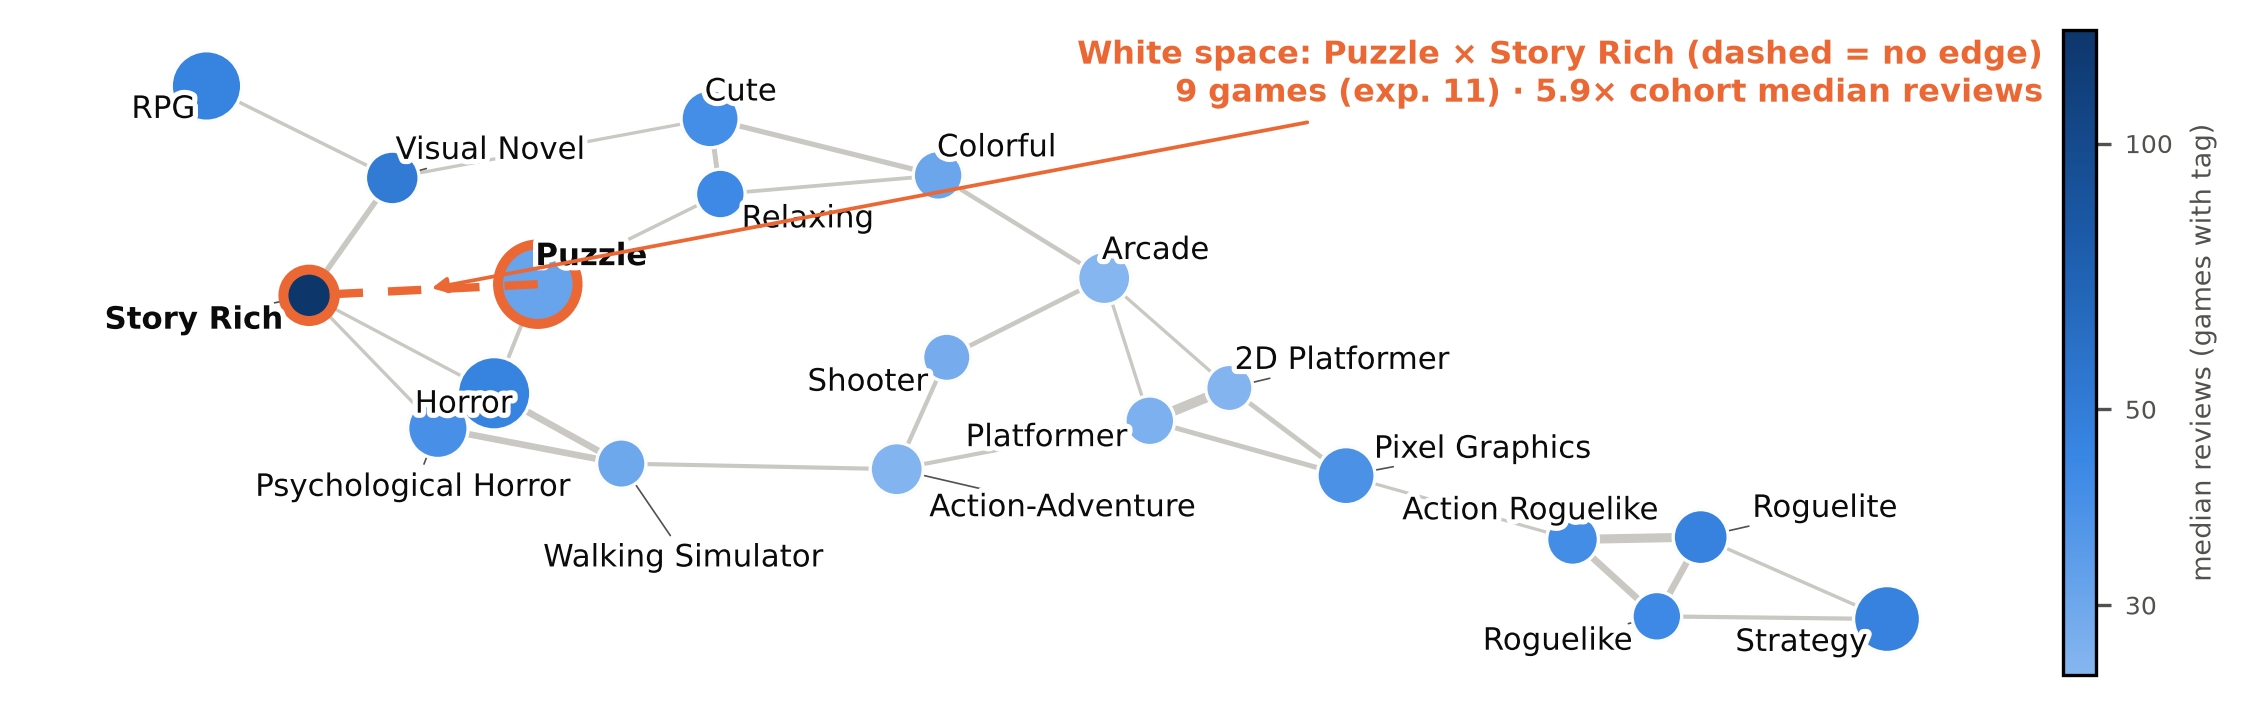

In [13]:
from matplotlib.colors import LinearSegmentedColormap, LogNorm
import matplotlib.patheffects as pe

INK, MUTED, EDGE, ACCENT = "#0b0b0b", "#52514e", "#c9c8c2", "#eb6834"
BLUES = LinearSegmentedColormap.from_list("seq", ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

baskets = R["baskets"]
tag_med = {t: float(np.median([reviews[i] for i, b in enumerate(baskets) if t in b])) for t in G}
focus = set(best) | {brokers.index[0]}
show = set(sorted(G, key=lambda t: -G.nodes[t]["n"])[:20]) | focus
H = G.subgraph(show).copy()
H = H.subgraph(max(nx.connected_components(H), key=len) | focus).copy()
# rebuild in sorted order: subgraph views iterate a Python set, which would make the layout hash-seed dependent
H2 = nx.Graph()
H2.add_nodes_from((t, G.nodes[t]) for t in sorted(H))
H2.add_edges_from(sorted((*sorted((u, v)), d) for u, v, d in H.edges(data=True)))
H = H2
pos = nx.kamada_kawai_layout(H, weight="dist")

fig, ax = plt.subplots(figsize=(7.6, 2.45), dpi=300)
norm = LogNorm(vmin=min(tag_med[t] for t in H), vmax=max(tag_med[t] for t in H))
widths = [0.4 + 3.2 * d["npmi"] for _, _, d in H.edges(data=True)]
nx.draw_networkx_edges(H, pos, ax=ax, width=widths, edge_color=EDGE)
sizes = [20 + 2.0 * H.nodes[t]["n"] for t in H]
nx.draw_networkx_nodes(H, pos, ax=ax, node_size=sizes, node_color=[tag_med[t] for t in H], cmap=BLUES,
                       vmin=norm.vmin, vmax=norm.vmax, linewidths=[2.4 if t in best else 0.8 for t in H],
                       edgecolors=[ACCENT if t in best else "#fcfcfb" for t in H])
# recommended pair: dashed bridge across the structural hole
(x1, y1), (x2, y2) = pos[best[0]], pos[best[1]]
ax.plot([x1, x2], [y1, y2], ls=(0, (4, 3)), color=ACCENT, lw=2.0, zorder=3)
texts = [ax.text(x, y, t, fontsize=7.4, color=INK, ha="center", va="center",
                 fontweight="bold" if t in focus else "normal",
                 path_effects=[pe.withStroke(linewidth=2.5, foreground="white")]) for t, (x, y) in pos.items()]
from adjustText import adjust_text
xy = np.array(list(pos.values()))
adjust_text(texts, x=xy[:, 0], y=xy[:, 1], ax=ax, expand=(1.15, 1.4), force_static=(0.4, 0.6), iter_lim=400,  # fixed iterations, not wall-clock
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.4))
# put the call-out in the emptiest corner of the plot
xs, ys = xy[:, 0], xy[:, 1]
fx = (xs - xs.min()) / (xs.max() - xs.min()); fy = (ys - ys.min()) / (ys.max() - ys.min())
corners = [(0.01, 0.99, "left", "top"), (0.99, 0.99, "right", "top"), (0.01, 0.01, "left", "bottom"),
           (0.99, 0.01, "right", "bottom")]
corner = min(corners, key=lambda c: (((fx - c[0]) / 0.35) ** 2 + ((fy - c[1]) / 0.5) ** 2 < 1).sum())
ax.annotate(f"White space: {best[0]} × {best[1]}{'' if G.has_edge(*best) else ' (dashed = no edge)'}\n{int(b.n_ab)} games (exp. {b.expected:.0f}) · "
            f"{b.lift:.1f}× cohort median reviews",
            ((x1 + x2) / 2, (y1 + y2) / 2), xytext=corner[:2], textcoords="axes fraction", ha=corner[2],
            va=corner[3], fontsize=7.6, color=ACCENT, fontweight="bold",
            arrowprops=dict(arrowstyle="-|>", color=ACCENT, lw=0.9, shrinkA=2, shrinkB=2))
sm = plt.cm.ScalarMappable(norm=norm, cmap=BLUES)
cb = fig.colorbar(sm, ax=ax, fraction=0.022, pad=0.0)
ticks = [t for t in [10, 20, 30, 50, 100, 200, 500] if norm.vmin <= t <= norm.vmax]
cb.set_ticks(ticks, labels=[str(t) for t in ticks])
cb.ax.minorticks_off()
cb.set_label("median reviews (games with tag)", fontsize=6.5, color=MUTED)
cb.ax.tick_params(labelsize=6, colors=MUTED)
ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "fig_network.png", dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(OUT / "fig_network.svg", bbox_inches="tight", facecolor="white")
NUM.update(fig_nodes=H.number_of_nodes(), fig_edges=H.number_of_edges())
(OUT / "numbers.json").write_text(json.dumps(NUM, indent=2, default=str))
plt.show()

## 9 · Sanity checks (fail loudly)

In [14]:
assert "Indie" not in G, "seed tag leaked into the graph"
assert not (set(G) & set(NUM["generic"])), "generic tag leaked into the graph"
assert not (set(G) & tn.NON_DESIGN), "non-design tag leaked into the graph"
assert "Indie" not in best and not (set(best) & set(NUM["generic"])), "recommended pair is an artifact"
assert NUM["nodes"] == G.number_of_nodes() and NUM["edges"] == G.number_of_edges()
assert NUM["analysed"] >= 950, "too many games missing live data"
assert NUM["steamspy_vs_s1_jaccard"] > 0.99 and NUM["tri_top5_jaccard"] < 0.99, "S2 should differ from S1, SteamSpy should not"
print("all checks passed")

all checks passed
